## Refresion: Student Performance

Ejemplo de regresión lineal múltiple para predecir la calificación final de un estudiante a partir de sus antecedentes académicos, hábitos de estudio y otras características.
Utilizaremos el dataset educativo Student Performance de UCI.

Algunas variables predictoras son:

* G1: Primera calificación
* G2: Segunda calificación
* studytime: Tiempo semanal de estudio, codificado por categorías
* failures: Cantidad de fracasos académicos previos
* absences:	Cantidad de ausencias
* age: Edad
* goout: Frecuencia de salidas con amigos
* higher: Intención de continuar estudios superiores

Pregunta que resolverá el modelo: ¿qué calificación final podría obtener un estudiante dadas sus características?
Una consideración importante: G1 y G2 son predictores muy informativos porque son calificaciones anteriores. Si queremos estimar el resultado antes de que se realicen las primeras evaluaciones, debemos excluirlas.

Dimensiones del dataset: (395, 33)

Primeros registros:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]

--- Evaluación del modelo ---
M

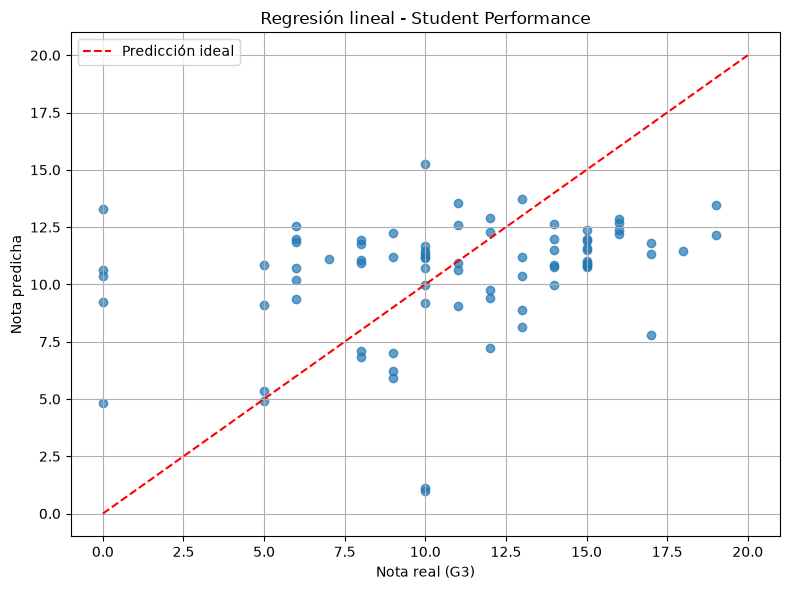


--- Predicción para un estudiante ---
Nota final estimada: 10.13 sobre 20
Nota estimada limitada al rango 0-20: 10.13


: 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Cargar el dataset de Matemática
url = (
    "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"
)

df = pd.read_csv(url, sep=";")

print("Dimensiones del dataset:", df.shape)
print("\nPrimeros registros:")
print(df.head())

# 2. Seleccionar variables
# Excluimos G1 y G2 para predecir sin utilizar
# las calificaciones de los períodos anteriores.

numericas = [
    "age", "studytime", "failures",
    "absences", "Medu", "Fedu"
]

categoricas = [
    "school", "sex", "address",
    "schoolsup", "famsup", "paid",
    "activities", "higher", "internet"
]

X = df[numericas + categoricas]
y = df["G3"]

# 3. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 4. Preparar el preprocesamiento
procesamiento_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median"))
])

procesamiento_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

preprocesador = ColumnTransformer([
    ("numericas", procesamiento_numerico, numericas),
    ("categoricas", procesamiento_categorico, categoricas)
])

# 5. Crear y entrenar el modelo
modelo = Pipeline([
    ("preprocesamiento", preprocesador),
    ("regresion", LinearRegression())
])

modelo.fit(X_train, y_train)

# 6. Realizar predicciones
y_pred = modelo.predict(X_test)

# 7. Evaluar el modelo
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("\n--- Evaluación del modelo ---")
print(f"MAE:  {mae:.2f} puntos")
print(f"RMSE: {rmse:.2f} puntos")
print(f"R²:   {r2:.4f}")

# 8. Graficar valores reales y predichos
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot([0, 20], [0, 20], "r--",
         label="Predicción ideal")

plt.xlabel("Nota real (G3)")
plt.ylabel("Nota predicha")
plt.title("Regresión lineal - Student Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 9. Predecir la nota de un nuevo estudiante
nuevo_estudiante = pd.DataFrame([{
    "age": 17,
    "studytime": 3,
    "failures": 0,
    "absences": 2,
    "Medu": 3,
    "Fedu": 2,
    "school": "GP",
    "sex": "F",
    "address": "U",
    "schoolsup": "no",
    "famsup": "yes",
    "paid": "no",
    "activities": "yes",
    "higher": "yes",
    "internet": "yes"
}])

prediccion = modelo.predict(nuevo_estudiante)[0]

print("\n--- Predicción para un estudiante ---")
print(f"Nota final estimada: {prediccion:.2f} sobre 20")
print(f"Nota estimada limitada al rango 0-20: "
      f"{max(0, min(20, prediccion)):.2f}")
